### What Are Embeddings?
Think of embeddings as a way to translate words into a language that computers understand - numbers!

In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Simplified 2D example (real embeddings have hundreds of dimensions)
word_embeddings = {
    "cat": [0.8, 0.6],
    "kitten": [0.75, 0.65],
    "dog": [0.7, 0.3],
    "puppy": [0.65, 0.35],
    "car": [-0.5, 0.2],
    "truck": [-0.45, 0.15]
}

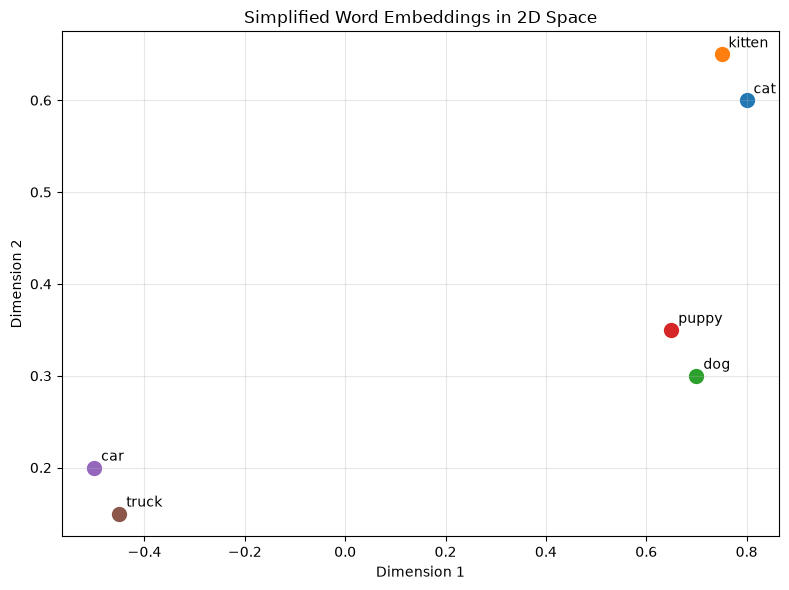

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))

for word, coords in word_embeddings.items():
    ax.scatter(coords[0], coords[1], s=100)
    ax.annotate(word, (coords[0], coords[1]), xytext=(5, 5), 
                textcoords='offset points')

ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('Simplified Word Embeddings in 2D Space')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Measurung Similarity

In [4]:
def cosine_similarity(vec1, vec2):
    """
    Cosine similarity measures the angle between two vectors.
    - Result close to 1: Very similar
    - Result close to 0: Not related
    - Result close to -1: Opposite meanings
    """

    dot_product=np.dot(vec1,vec2)
    norm_a=np.linalg.norm(vec1)
    norm_b=np.linalg.norm(vec2)
    return dot_product/(norm_a * norm_b)



In [5]:
# Example
cat_vector = [0.8, 0.6, 0.3]
kitten_vector = [0.75, 0.65, 0.35]
car_vector = [-0.5, 0.2, 0.1]

cat_kitten_similarity=cosine_similarity(cat_vector,kitten_vector)
print(cat_kitten_similarity)

0.9966186334192183


In [6]:
cosine_similarity(cat_vector,car_vector)

np.float64(-0.4371858854891681)

### Creating your first embeddings

In [7]:
### Huggingface And OpenAI Models

from langchain_huggingface import HuggingFaceEmbeddings

## Initialize a simple Embedding model(no API Key needed!)
embeddings=HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-mpnet-base-v2"
)
embeddings




c:\Users\kamak\Desktop\RAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1280.48it/s]


HuggingFaceEmbeddings(model_name='sentence-transformers/all-mpnet-base-v2', cache_folder=None, model_kwargs={}, encode_kwargs={}, query_encode_kwargs={}, multi_process=False, show_progress=False)

In [8]:
## create your first embeddings
text="Hello, I am learning about embeddings!"

embedding=embeddings.embed_query(text)
print(f"Text: {text}")
print(f"Embedding length : {len(embedding)}")
print(embedding)


Text: Hello, I am learning about embeddings!
Embedding length : 768
[0.007487542927265167, -0.09695898741483688, -0.03398934379220009, 0.0743582472205162, 0.03719722107052803, 0.028060050681233406, 0.03480540215969086, -0.02724340558052063, 0.0606587715446949, 0.016743896529078484, 0.026571722701191902, -0.004313203040510416, 0.0006282417452894151, 0.013757879845798016, 0.0862957090139389, -0.09514079242944717, 0.06359191983938217, 0.031184421852231026, -0.030264370143413544, -0.02112019620835781, 0.028054460883140564, -0.04642486572265625, -0.013827016577124596, 0.02649993635714054, -0.024046652019023895, 0.023655496537685394, 0.0024544803891330957, -0.04627960920333862, 0.004411950707435608, -0.025507722049951553, -0.009828848764300346, -0.01821957156062126, 0.06454159319400787, -0.012169338762760162, 1.6369166360163945e-06, -0.004010328091681004, -0.021304721012711525, -0.005248049274086952, 0.005810948554426432, -0.022599542513489723, 0.00744611443951726, 0.029232988134026527, -0.0

In [9]:
sentences = [
    "The cat sat on the mat",
    "The cat sat on the mat",
    "The dog played in the yard",
    "I love programming in Python",
    "Python is my favorite programming language"
]

embedding_sentence=embeddings.embed_documents(sentences)

print(embedding_sentence[0])
print(embedding_sentence[1])

[-0.004790385253727436, -0.044546373188495636, -0.012947138398885727, -0.015809960663318634, 0.016215022653341293, -0.042388733476400375, -0.017240505665540695, -0.00916895642876625, 0.060414571315050125, 0.008282063528895378, 0.05595816299319267, 0.030417388305068016, -0.01675654575228691, -0.007216830737888813, 0.04726509377360344, 0.08785630017518997, 0.0011019745143130422, 0.042305007576942444, 0.02570975571870804, -0.00953593384474516, 0.02513871341943741, 0.004655050113797188, -0.00011651922977762297, 0.027523545548319817, -0.07715404033660889, 0.008260990492999554, -0.044578343629837036, -0.012338440865278244, -0.039780307561159134, -0.02995501458644867, 0.03811981901526451, 0.02583957463502884, 0.010295752435922623, -0.10166219621896744, 1.752128582666046e-06, -0.0063080252148211, -0.025119490921497345, -0.00696757435798645, 0.1041608601808548, -0.06334690004587173, -0.03254329413175583, -0.036750346422195435, 0.0031976518221199512, -0.005808977410197258, 0.048912763595581055, 

In [10]:
from langchain_huggingface import HuggingFaceEmbeddings
import time

# Popular models comparison
models = {
    "all-MiniLM-L6-v2": {
        "size": 384,
        "description": "Fast and efficient, good quality",
        "use_case": "General purpose, real-time applications"
    },
    "all-mpnet-base-v2": {
        "size": 768,
        "description": "Best quality, slower than MiniLM",
        "use_case": "When quality matters more than speed"
    },
    "all-MiniLM-L12-v2": {
        "size": 384,
        "description": "Slightly better than L6, bit slower",
        "use_case": "Good balance of speed and quality"
    },
    "multi-qa-MiniLM-L6-cos-v1": {
        "size": 384,
        "description": "Optimized for question-answering",
        "use_case": "Q&A systems, semantic search"
    },
    "paraphrase-multilingual-MiniLM-L12-v2": {
        "size": 384,
        "description": "Supports 50+ languages",
        "use_case": "Multilingual applications"
    }
}

print("📊 Popular Open Source Embedding Models:\n")
for model_name, info in models.items():
    print(f"Model: sentence-transformers/{model_name}")
    print(f"  📏 Embedding size: {info['size']} dimensions")
    print(f"  📝 Description: {info['description']}")
    print(f"  🎯 Use case: {info['use_case']}\n")


📊 Popular Open Source Embedding Models:

Model: sentence-transformers/all-MiniLM-L6-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Fast and efficient, good quality
  🎯 Use case: General purpose, real-time applications

Model: sentence-transformers/all-mpnet-base-v2
  📏 Embedding size: 768 dimensions
  📝 Description: Best quality, slower than MiniLM
  🎯 Use case: When quality matters more than speed

Model: sentence-transformers/all-MiniLM-L12-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Slightly better than L6, bit slower
  🎯 Use case: Good balance of speed and quality

Model: sentence-transformers/multi-qa-MiniLM-L6-cos-v1
  📏 Embedding size: 384 dimensions
  📝 Description: Optimized for question-answering
  🎯 Use case: Q&A systems, semantic search

Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Supports 50+ languages
  🎯 Use case: Multilingual applications



### Gemini Embeddings

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
os.environ["GEMINI_API_KEY"]=os.getenv("GEMINI_API_KEY")

In [10]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings
embeddingx=GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

In [11]:
embeddingx

GoogleGenerativeAIEmbeddings(client=<google.genai.client.Client object at 0x0000019C1B4C3ED0>, model='gemini-embedding-001', task_type=None, google_api_key=SecretStr('**********'), credentials=None, vertexai=None, project=None, location=None, base_url=None, additional_headers=None, client_args=None, api_version=None, request_options=None, output_dimensionality=None)

In [12]:
## Single text embeddings
single_text="Langchain and Rag are amazing frameworks and projects to work on"
single_embeddings=embeddingx.embed_query(single_text)
print(len(single_embeddings))
print(single_embeddings)

3072
[-0.024723664, -0.0029875536, 0.009309707, -0.074158706, -0.022686219, -0.0006884016, -0.0032035194, 0.02810353, 0.010192243, -0.002992377, 0.0035433946, -0.018109305, 0.029240591, 0.031313546, 0.12878494, -0.0026795443, 0.0031924096, 0.0013709897, -0.0030112783, -0.0076521304, -0.0035409054, 0.015943829, 0.02762074, 0.0054150904, 0.008436863, 0.0025464173, 0.02277423, -0.007467847, 0.020592945, 0.020889768, -0.001445603, -0.008471491, -0.003145744, 0.017389728, 0.0064752414, 0.014882929, 0.022176234, -0.013709253, 0.007912171, 0.019186126, 0.009246572, 0.00112715, -0.0009973675, -0.030073877, -0.027120395, -0.012398551, 0.0006087151, -0.011352806, -0.0070452914, 0.008923025, -0.023980241, -0.016358849, 0.005832909, -0.16179158, 0.012752278, 0.010721661, -0.008666011, 0.016517086, 0.036552444, 0.019867493, 0.0037092061, 0.01032958, -0.02592432, -0.00011135696, -0.006730929, -0.025133403, 0.008974302, -0.030545775, -0.02521938, -0.017459344, 0.01893306, -0.0069597545, 0.0063470816,

In [ ]:
print("📝 Single Text Embedding:")
print(f"Input: {single_text}")
print(f"Output: Vector of {len(single_embeddings)} dimensions")
print(f"Sample values: {single_embeddings[:5]}")

📝 Single Text Embedding:
Input: Langchain and Rag are amazing frameworks and projects to work on
Output: Vector of 384 dimensions
Sample values: [-0.11133593320846558, -0.02833968959748745, 0.03342413529753685, -0.07949576526880264, -0.01831606775522232]


In [13]:
# Example 2: Multiple texts at once
multiple_texts = [
    "Python is a programming language",
    "LangChain is a framework for LLM applications",
    "Embeddings convert text to numbers",
    "Vectors can be compared for similarity"
]

In [14]:
multiple_embeddings = embeddingx.embed_documents(multiple_texts)

In [ ]:
multiple_embeddings

[[-0.035370830446481705,
  0.03816499933600426,
  -0.041260089725255966,
  0.01606883853673935,
  -0.03836705535650253,
  -0.1344706118106842,
  0.03573702275753021,
  0.04229675605893135,
  -0.03464673087000847,
  -0.026432035490870476,
  -0.04449029266834259,
  0.024482280015945435,
  0.09475179761648178,
  0.017094921320676804,
  0.056999169290065765,
  -0.054718200117349625,
  -0.08704376220703125,
  -0.004238331224769354,
  0.019994890317320824,
  -0.11494337767362595,
  -0.036741845309734344,
  0.059062130749225616,
  -0.03329761326313019,
  0.023044906556606293,
  0.015700502321124077,
  -0.003246092703193426,
  -0.009961205534636974,
  -0.01881147362291813,
  0.023121865466237068,
  -0.0023967779707163572,
  -0.05237286537885666,
  0.09519387036561966,
  0.05609035864472389,
  0.03423016890883446,
  0.018951309844851494,
  0.059599824249744415,
  -0.00556279206648469,
  -0.09742437303066254,
  -0.05595190078020096,
  0.0033041874412447214,
  -0.06094692274928093,
  0.0164042953

In [15]:
print("\n📚 Multiple Text Embeddings:")
print(f"Number of texts: {len(multiple_texts)}")
print(f"Number of embeddings: {len(multiple_embeddings)}")
print(f"Each embedding size: {len(multiple_embeddings[0])}")


📚 Multiple Text Embeddings:
Number of texts: 4
Number of embeddings: 4
Each embedding size: 3072


In [ ]:
multiple_embeddings[0]

[-0.035370830446481705,
 0.03816499933600426,
 -0.041260089725255966,
 0.01606883853673935,
 -0.03836705535650253,
 -0.1344706118106842,
 0.03573702275753021,
 0.04229675605893135,
 -0.03464673087000847,
 -0.026432035490870476,
 -0.04449029266834259,
 0.024482280015945435,
 0.09475179761648178,
 0.017094921320676804,
 0.056999169290065765,
 -0.054718200117349625,
 -0.08704376220703125,
 -0.004238331224769354,
 0.019994890317320824,
 -0.11494337767362595,
 -0.036741845309734344,
 0.059062130749225616,
 -0.03329761326313019,
 0.023044906556606293,
 0.015700502321124077,
 -0.003246092703193426,
 -0.009961205534636974,
 -0.01881147362291813,
 0.023121865466237068,
 -0.0023967779707163572,
 -0.05237286537885666,
 0.09519387036561966,
 0.05609035864472389,
 0.03423016890883446,
 0.018951309844851494,
 0.059599824249744415,
 -0.00556279206648469,
 -0.09742437303066254,
 -0.05595190078020096,
 0.0033041874412447214,
 -0.06094692274928093,
 0.016404295340180397,
 -0.05196293815970421,
 -0.03670

In [17]:

from langchain_google_genai import GoogleGenerativeAIEmbeddings

# Different Google Gemini embedding models
models_comparison = {
    "gemini-embedding-2-preview": {
        "dimensions": "3072 (Flexible 128-3072 via MRL)",
        "description": "Flagship natively multimodal model. Accepts text, images, video, audio, and PDFs.",
        "cost_per_1m_tokens": 0.20, # Text input cost ($0.45 for images, $6.50 for audio)
        "use_case": "State-of-the-art multilingual RAG, cross-modal semantic search, & agentic workflows"
    },
    "gemini-embedding-001": {
        "dimensions": 3072,
        "description": "First-generation general-purpose text-only embedding model.",
        "cost_per_1m_tokens": 0.15,
        "use_case": "Standard text classification, clustering, and legacy text-based RAG"
    }
}

# Display comparison
print("📊 Google Gemini Embedding Models Comparison:\n")
for model_name, details in models_comparison.items():
    print(f"Model: {model_name}")
    print(f"  📏 Dimensions: {details['dimensions']}")
    print(f"  💰 Cost: ${details['cost_per_1m_tokens']}/1M text tokens")
    print(f"  📝 Description: {details['description']}")
    print(f"  🎯 Use case: {details['use_case']}\n")


📊 Google Gemini Embedding Models Comparison:

Model: gemini-embedding-2-preview
  📏 Dimensions: 3072 (Flexible 128-3072 via MRL)
  💰 Cost: $0.2/1M text tokens
  📝 Description: Flagship natively multimodal model. Accepts text, images, video, audio, and PDFs.
  🎯 Use case: State-of-the-art multilingual RAG, cross-modal semantic search, & agentic workflows

Model: gemini-embedding-001
  📏 Dimensions: 3072
  💰 Cost: $0.15/1M text tokens
  📝 Description: First-generation general-purpose text-only embedding model.
  🎯 Use case: Standard text classification, clustering, and legacy text-based RAG



### Cosine Similarity With Gemini Embeddings


In [18]:
# Example 1: Finding similar sentences
sentences = [
    "The cat sat on the mat",
    "A feline rested on the rug",
    "The dog played in the yard",
    "I love programming in Python",
    "Python is my favorite programming language"
]

In [19]:
import numpy as np
def cosine_similarity(vec1, vec2):
    """
    Cosine similarity measures the angle between two vectors.
    - Result close to 1: Very similar
    - Result close to 0: Not related
    - Result close to -1: Opposite meanings
    """

    dot_product=np.dot(vec1,vec2)
    norm_a=np.linalg.norm(vec1)
    norm_b=np.linalg.norm(vec2)
    return dot_product/(norm_a * norm_b)

In [22]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings
embeddings=GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")
embeddings

GoogleGenerativeAIEmbeddings(client=<google.genai.client.Client object at 0x0000019C2991D940>, model='gemini-embedding-001', task_type=None, google_api_key=SecretStr('**********'), credentials=None, vertexai=None, project=None, location=None, base_url=None, additional_headers=None, client_args=None, api_version=None, request_options=None, output_dimensionality=None)

In [23]:
sentence_embeddings=embeddings.embed_documents(sentences)
sentence_embeddings

[[-0.020273827,
  0.021387203,
  0.0109888585,
  -0.0946949,
  0.0032593862,
  0.0016573805,
  -0.003855524,
  0.00807022,
  0.014376951,
  0.019213004,
  0.002420615,
  -0.01675143,
  -0.010258527,
  0.0008397154,
  0.14146619,
  0.005391268,
  -0.0050069126,
  0.012536185,
  -0.009372957,
  -0.0324653,
  0.010522589,
  -0.0027480058,
  0.013321872,
  -0.012734432,
  -0.0120055545,
  -0.009109527,
  0.010548128,
  0.014888071,
  0.028214354,
  -0.0112648485,
  0.0013896069,
  0.043458078,
  -0.016450256,
  -0.0018418576,
  -0.020037321,
  0.014874125,
  0.017732717,
  -0.02632252,
  0.00900231,
  0.017905893,
  0.00036645125,
  -0.0061063156,
  -0.021427661,
  -0.010786575,
  0.022649813,
  0.0045570508,
  0.0053027975,
  0.000864682,
  0.027498683,
  0.007778515,
  0.0003966219,
  0.022844283,
  -0.022159101,
  -0.2483037,
  -0.0052004373,
  0.0054841787,
  -0.0042362777,
  0.0019316657,
  0.002753109,
  0.007226569,
  -0.012612498,
  0.018492283,
  -0.014255642,
  -0.015889123,
  0.

In [24]:
## Calculate the simialrity betwween all pairs

for i in range(len(sentences)):
    for j in range(i+1,len(sentences)):
        similarity=cosine_similarity(sentence_embeddings[i],sentence_embeddings[j])

        print(f"'{sentences[i]}' vs '{sentences[j]}'")
        print(f"Similarity: {similarity:.3f}\n")


'The cat sat on the mat' vs 'A feline rested on the rug'
Similarity: 0.894

'The cat sat on the mat' vs 'The dog played in the yard'
Similarity: 0.834

'The cat sat on the mat' vs 'I love programming in Python'
Similarity: 0.748

'The cat sat on the mat' vs 'Python is my favorite programming language'
Similarity: 0.756

'A feline rested on the rug' vs 'The dog played in the yard'
Similarity: 0.804

'A feline rested on the rug' vs 'I love programming in Python'
Similarity: 0.721

'A feline rested on the rug' vs 'Python is my favorite programming language'
Similarity: 0.724

'The dog played in the yard' vs 'I love programming in Python'
Similarity: 0.724

'The dog played in the yard' vs 'Python is my favorite programming language'
Similarity: 0.730

'I love programming in Python' vs 'Python is my favorite programming language'
Similarity: 0.972



In [25]:
### Example- Semantic Search- Retireve the similar sentence
# Test semantic search
documents = [
    "LangChain is a framework for developing applications powered by language models",
    "Python is a high-level programming language",
    "Machine learning is a subset of artificial intelligence",
    "Embeddings convert text into numerical vectors",
    "The weather today is sunny and warm"
]
query="What is Langchain?"

In [26]:
def semantic_search(query,documents,embeddings_models,top_k=3):
    """Simple semantic search implementation"""

    ## embed query and doument

    query_embedding=embeddings_models.embed_query(query)
    doc_embeddings = embeddings_models.embed_documents(documents)

    ## Calculate the similarity score

    similarties=[]

    for i,doc_emb in enumerate(doc_embeddings):
        similarity=cosine_similarity(query_embedding,doc_emb)
        similarties.append((similarity,documents[i]))

    ## Sort by similarity
    similarties.sort(reverse=True)
    return similarties[:top_k]



In [27]:
results=semantic_search(query,documents,embeddings)
results

[(np.float64(0.7854254630881178),
  'LangChain is a framework for developing applications powered by language models'),
 (np.float64(0.6374986188307026),
  'Embeddings convert text into numerical vectors'),
 (np.float64(0.61572529346463), 'Python is a high-level programming language')]

In [28]:
print(f"\n🔎 Semantic Search Results for: '{query}'")
for score, doc in results:
    print(f"Score: {score:.3f} | {doc}")


🔎 Semantic Search Results for: 'What is Langchain?'
Score: 0.785 | LangChain is a framework for developing applications powered by language models
Score: 0.637 | Embeddings convert text into numerical vectors
Score: 0.616 | Python is a high-level programming language


In [29]:
query="What is Embeddings?"
results=semantic_search(query,documents,embeddings)
results

[(np.float64(0.7882930054866422),
  'Embeddings convert text into numerical vectors'),
 (np.float64(0.6569544848808396),
  'LangChain is a framework for developing applications powered by language models'),
 (np.float64(0.6332447400012686),
  'Machine learning is a subset of artificial intelligence')]

In [30]:
print(f"\n🔎 Semantic Search Results for: '{query}'")
for score, doc in results:
    print(f"Score: {score:.3f} | {doc}")


🔎 Semantic Search Results for: 'What is Embeddings?'
Score: 0.788 | Embeddings convert text into numerical vectors
Score: 0.657 | LangChain is a framework for developing applications powered by language models
Score: 0.633 | Machine learning is a subset of artificial intelligence
